# PlantTraitNet on your own plant photos (Google Colab)

Predicts **plant height, leaf area, specific leaf area (SLA) and leaf nitrogen (LN)** plus an uncertainty for each,
using the pretrained PlantTraitNet model.

**Before you start**
1. `Runtime → Change runtime type → T4 GPU → Save`.
2. Put your photos in Google Drive in the folder **`MyDrive/PlantTraitNet/my_plants/`** (jpg/jpeg/png).
3. Run the cells top to bottom (`Runtime → Run all` works once the settings in Step 2 are filled in).

## Step 1 — Check the GPU

In [ ]:
!nvidia-smi
import torch
print("CUDA available:", torch.cuda.is_available())

## Step 2 — Mount Google Drive and set your options
`DEFAULT_LAT` / `DEFAULT_LON` are used for photos without GPS data in their EXIF (e.g. Pullman, WA below).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_DIR   = '/content/drive/MyDrive/PlantTraitNet'   # everything is cached/saved here
IMAGES_DIR  = f'{DRIVE_DIR}/my_plants'                 # your photos
CKPT_DIR    = f'{DRIVE_DIR}/checkpoints'               # 1.8 GB per checkpoint, downloaded once
RESULTS_DIR = f'{DRIVE_DIR}/results'
DEFAULT_LAT, DEFAULT_LON = 46.73, -117.18              # used when a photo has no GPS
SEEDS = [0]                                            # use [0, 100, 200] for a 3-model ensemble (needs ~5.5 GB of Drive)

for d in (IMAGES_DIR, CKPT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)
print('Images found:', len([f for f in os.listdir(IMAGES_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]))

Mounted at /content/drive
Images found: 1


## Step 3 — Get the code (PlantTraitNet + Depth-Anything-V2)

In [2]:
%cd /content
!git clone -q https://github.com/GeoSense-Freiburg/PlantTraitNet.git
!git clone -q https://github.com/DepthAnything/Depth-Anything-V2.git
!ls /content/PlantTraitNet/src

/content
benchmarking  datasets	 fusion        loss_util  params.yaml  utils
configs       filtering  inference.py  models	  train.py


## Step 4 — Install dependencies (~3–5 min)
The repo pins `mmcv==1.3.14`, which does not build on Colab's Python. The code only uses mmcv's `Registry` and
checkpoint loader, so this cell tries `mmcv==1.7.2` and, if that fails, installs a tiny drop-in replacement.

In [3]:
!pip install -q omegaconf termcolor timm python-box pyproj shapely rioxarray xarray rshf huggingface_hub
!MMCV_WITH_OPS=0 pip install -q "mmcv==1.7.2" "yapf==0.40.1"

import subprocess, sys, textwrap, os
ok = subprocess.run([sys.executable, '-c', 'import mmcv.utils, mmcv.runner']).returncode == 0
if ok:
    print('mmcv installed OK')
else:
    print('mmcv failed to import -> installing minimal mmcv shim')
    shim = '/content/mmcv_shim/mmcv'
    os.makedirs(shim, exist_ok=True)
    open(f'{shim}/__init__.py', 'w').write('')
    open(f'{shim}/utils.py', 'w').write(textwrap.dedent('''
        class Registry:
            def __init__(self, name):
                self.name, self._module_dict = name, {}
            def register_module(self, name=None, force=False, module=None):
                def _register(cls):
                    self._module_dict[name or cls.__name__] = cls
                    return cls
                return _register(module) if module is not None else _register
            def get(self, key):
                return self._module_dict.get(key)
            def build(self, cfg, default_args=None):
                cfg = dict(cfg)
                obj_type = cfg.pop('type')
                if obj_type not in self._module_dict:
                    raise KeyError(f'{obj_type} is not in the {self.name} registry')
                return self._module_dict[obj_type](**cfg)
    '''))
    open(f'{shim}/runner.py', 'w').write(textwrap.dedent('''
        import torch
        class CheckpointLoader:
            @staticmethod
            def load_checkpoint(filename, map_location=None, **kwargs):
                return torch.load(filename, map_location=map_location, weights_only=False)
    '''))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 86.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 87.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 607.8/607.8 kB 16.9 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue

## Step 5 — Fix the config and add the prediction script
* `default.yml` names the geo encoder `Climplicit`, but the class is registered as `ClimplicitModel`.
* `predict_my_images.py` runs the model on images **without** ground-truth labels (the repo's `inference.py` needs labels
  and an unpublished scaler file).

In [4]:
cfg_path = '/content/PlantTraitNet/src/configs/default.yml'
cfg_text = open(cfg_path).read()
cfg_text = cfg_text.replace('type: Climplicit\n', 'type: ClimplicitModel\n')
open(cfg_path, 'w').write(cfg_text)
!grep -n "Climplicit" {cfg_path}

59:      type: ClimplicitModel


In [5]:
%%writefile /content/PlantTraitNet/src/predict_my_images.py
# ---------------------------------------------------------
# Predict plant traits for your own photos with a pretrained PlantTraitNet checkpoint.
#
# Input CSV columns: Image (path, absolute or relative to --image_root), Latitude, Longitude
# Output CSV: one row per image with <trait>_pred_norm, <trait>_logvar, <trait>_sigma_norm
#             and, if --scaler is given, <trait>_pred in real units.
#
# Unlike inference.py, this script needs no ground-truth labels and no PFT column.
# ---------------------------------------------------------

import argparse
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from omegaconf import OmegaConf

from datasets.builder import build_img_transform
from models import build_model


def parse_args():
    parser = argparse.ArgumentParser("PlantTraitNet prediction on custom images")
    parser.add_argument("--cfg", type=str, default="configs/default.yml")
    parser.add_argument("--checkpoint", type=str, required=True, help="Path to e.g. multitrait_seed0.pth")
    parser.add_argument("--images_csv", type=str, required=True, help="CSV with Image, Latitude, Longitude")
    parser.add_argument("--image_root", type=str, default=".", help="Folder that relative Image paths are under")
    parser.add_argument("--output", type=str, default="my_predictions.csv")
    parser.add_argument("--scaler", type=str, default=None, help="Optional target transformer .pkl")
    parser.add_argument("--batch_size", type=int, default=16)
    return parser.parse_args()


def load_image(path, transform):
    img = Image.open(path).convert("RGB")
    img = ImageOps.exif_transpose(img)
    return transform(img)


@torch.no_grad()
def predict_batch(model, images, geo):
    # Same steps as PlantTraitNet.forward_test, but without the hard-coded .cuda() calls
    embeddings = model.fusion({
        "image": model.image_encoder(images),
        "depthmap": model.depth_encoder(images),
        "geo": model.geo_encoder.forward_feature(geo),
    })
    if model.layernorm is not None:
        embeddings = model.layernorm(embeddings.float())
    embeddings = model.input_proj(embeddings)
    return model.multimodal(embeddings)


def main():
    args = parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    cfg = OmegaConf.load(args.cfg)
    traits = list(cfg.data.target_prefix)

    model = build_model(cfg.model)
    checkpoint = torch.load(args.checkpoint, map_location="cpu", weights_only=False)
    msg = model.load_state_dict(checkpoint["model"], strict=False)
    # A non-empty list here means the config does not match the checkpoint
    print(f"Missing keys: {len(msg.missing_keys)}  Unexpected keys: {len(msg.unexpected_keys)}")
    if msg.missing_keys:
        print("  first missing:", msg.missing_keys[:5])
    model.to(device).eval()

    scaler = joblib.load(args.scaler) if args.scaler else None
    transform = build_img_transform("test")
    df = pd.read_csv(args.images_csv)

    rows = []
    for start in range(0, len(df), args.batch_size):
        chunk = df.iloc[start:start + args.batch_size]
        paths = [Path(p) if Path(p).is_absolute() else Path(args.image_root) / p for p in chunk["Image"]]
        images = torch.stack([load_image(p, transform) for p in paths]).to(device)
        geo = torch.tensor(chunk[["Longitude", "Latitude"]].values, dtype=torch.float, device=device)

        mu, log_var = predict_batch(model, images, geo)
        mu, log_var = mu.cpu().numpy(), log_var.cpu().numpy()
        real = scaler.inverse_transform(mu) if scaler is not None else None

        for i in range(len(chunk)):
            row = {"Image": chunk["Image"].iloc[i]}
            for j, trait in enumerate(traits):
                row[f"{trait}_pred_norm"] = mu[i, j]
                row[f"{trait}_logvar"] = log_var[i, j]
                row[f"{trait}_sigma_norm"] = float(np.exp(0.5 * log_var[i, j]))
                if real is not None:
                    row[f"{trait}_pred"] = real[i, j]
            rows.append(row)
        print(f"Processed {min(start + args.batch_size, len(df))}/{len(df)} images")

    out = pd.concat([df.reset_index(drop=True), pd.DataFrame(rows).drop(columns="Image")], axis=1)
    out.to_csv(args.output, index=False)
    print(f"Saved predictions to {args.output}")


if __name__ == "__main__":
    main()

Writing /content/PlantTraitNet/src/predict_my_images.py


## Step 6 — Download the pretrained checkpoint(s) into Drive (only the first time)

In [6]:
from huggingface_hub import hf_hub_download
for seed in SEEDS:
    name = f'multitrait_seed{seed}.pth'
    if os.path.exists(f'{CKPT_DIR}/{name}'):
        print('Already in Drive:', name)
    else:
        hf_hub_download('ayushi3536/PlantTraitNet', name, local_dir=CKPT_DIR)
        print('Downloaded:', name)

Already in Drive: multitrait_seed0.pth


## Step 7 — Build the image list (reads GPS from each photo's EXIF)
Writes `my_plants.csv` to Drive. You can edit it in Drive (e.g. fix coordinates, add a `Species` column) and re-run Step 8.

In [7]:
import pandas as pd
from PIL import Image, ExifTags

def exif_gps(path):
    try:
        gps = Image.open(path).getexif().get_ifd(ExifTags.IFD.GPSInfo)
        if not gps:
            return None
        def to_deg(v):
            d, m, s = (float(x) for x in v)
            return d + m / 60 + s / 3600
        lat, lon = to_deg(gps[2]), to_deg(gps[4])
        if gps.get(1) == 'S': lat = -lat
        if gps.get(3) == 'W': lon = -lon
        return lat, lon
    except Exception:
        return None

csv_path = f'{DRIVE_DIR}/my_plants.csv'
if os.path.exists(csv_path):
    meta = pd.read_csv(csv_path)
    print('Using existing', csv_path, '(delete it to rebuild from EXIF)')
else:
    rows = []
    for f in sorted(os.listdir(IMAGES_DIR)):
        if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue
        gps = exif_gps(os.path.join(IMAGES_DIR, f))
        lat, lon = gps if gps else (DEFAULT_LAT, DEFAULT_LON)
        rows.append({'Image': f, 'Latitude': lat, 'Longitude': lon, 'gps_from_exif': gps is not None})
    meta = pd.DataFrame(rows)
    meta.to_csv(csv_path, index=False)
meta

Using existing /content/drive/MyDrive/PlantTraitNet/my_plants.csv (delete it to rebuild from EXIF)


,Image,Latitude,Longitude,gps_from_exif,species
0,img1.jpg,39.40273,-9.128,False,Phytolacca heterotepala


## Step 8 — Run PlantTraitNet
Check the line `Missing keys: 0`. A large number means the config does not match the checkpoint and results are invalid.

In [8]:
for seed in SEEDS:
    out = f'{RESULTS_DIR}/predictions_seed{seed}.csv'
    ckpt = f'{CKPT_DIR}/multitrait_seed{seed}.pth'
    !cd /content/PlantTraitNet/src && PYTHONPATH=/content/mmcv_shim:/content/Depth-Anything-V2 python predict_my_images.py --cfg configs/default.yml --checkpoint "{ckpt}" --images_csv "{csv_path}" --image_root "{IMAGES_DIR}" --output "{out}" --batch_size 32

xFormers not available
xFormers not available
Using device: cuda
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
2026-10-19 01:48:23,987 - dinov2 - INFO - using MLP layer as FFN
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitb14/dinov2_vitb14_reg4_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitb14_reg4_pretrain.pth
100% 330M/330M [00:01<00:00, 312MB/s]
2

## Step 9 — Look at the results
`*_pred_norm` = predicted trait on the model's normalized scale (higher = taller / larger leaves / higher SLA / more N).
`*_sigma_norm` = model uncertainty (higher = trust less). Real units need the authors' scaler file, which is not public.

In [9]:
import numpy as np
TRAITS = ['Height', 'LeafArea', 'SLA', 'Leaf_N']
runs = [pd.read_csv(f'{RESULTS_DIR}/predictions_seed{s}.csv') for s in SEEDS]
res = runs[0][['Image', 'Latitude', 'Longitude']].copy()
for t in TRAITS:
    res[f'{t}_pred_norm']  = np.mean([r[f'{t}_pred_norm'] for r in runs], axis=0)
    res[f'{t}_sigma_norm'] = np.mean([r[f'{t}_sigma_norm'] for r in runs], axis=0)
    if len(runs) > 1:
        res[f'{t}_seed_std'] = np.std([r[f'{t}_pred_norm'] for r in runs], axis=0)
    # flag the least certain 20% of your photos for each trait
    res[f'{t}_uncertain'] = res[f'{t}_sigma_norm'] > res[f'{t}_sigma_norm'].quantile(0.8)

res.to_csv(f'{RESULTS_DIR}/predictions_final.csv', index=False)
res.round(3)

,Image,Latitude,Longitude,Height_pred_norm,Height_sigma_norm,Height_uncertain,LeafArea_pred_norm,LeafArea_sigma_norm,LeafArea_uncertain,SLA_pred_norm,SLA_sigma_norm,SLA_uncertain,Leaf_N_pred_norm,Leaf_N_sigma_norm,Leaf_N_uncertain
0,img1.jpg,39.403,-9.128,0.061,0.094,False,0.067,0.211,False,0.447,0.2,False,0.521,0.26,False


### Photos with their predictions

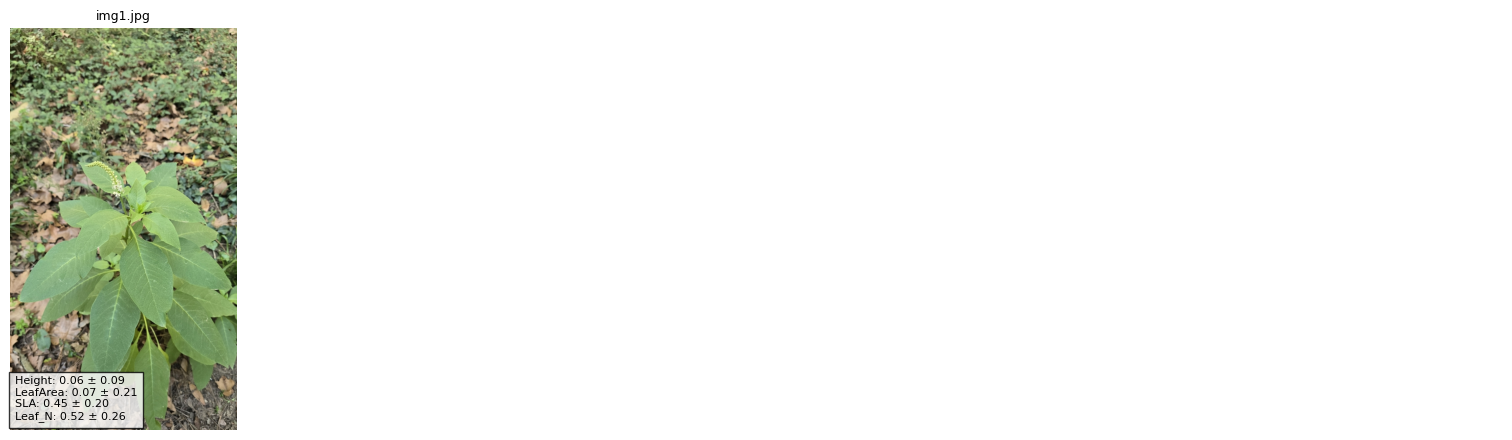

In [10]:
import matplotlib.pyplot as plt
from PIL import ImageOps
n = min(len(res), 12)
cols = 4
fig, axes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(16, 4.5 * np.ceil(n / cols)), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, (_, r) in zip(axes.flat, res.head(n).iterrows()):
    ax.imshow(ImageOps.exif_transpose(Image.open(os.path.join(IMAGES_DIR, r['Image']))))
    ax.set_title(r['Image'], fontsize=9)
    txt = '\n'.join(f"{t}: {r[f'{t}_pred_norm']:.2f} ± {r[f'{t}_sigma_norm']:.2f}" for t in TRAITS)
    ax.text(0.02, 0.02, txt, transform=ax.transAxes, fontsize=8, va='bottom',
            bbox=dict(facecolor='white', alpha=0.8))
plt.tight_layout(); plt.show()

### Compare plants across traits

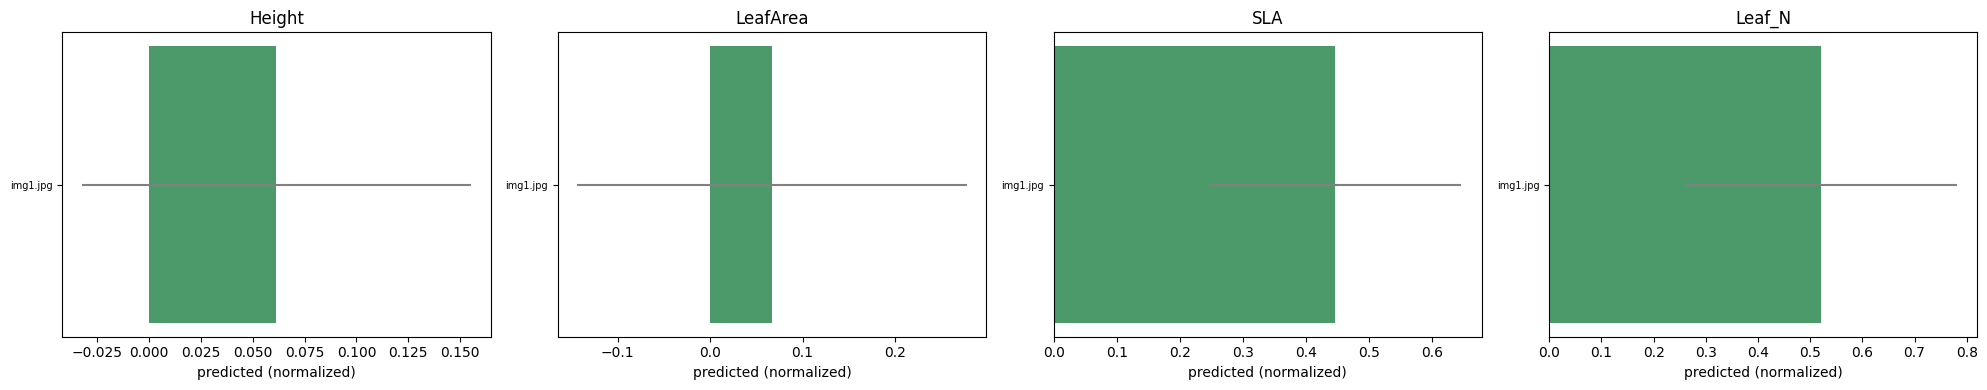

Correlation SLA vs Leaf N: nan


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2991: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


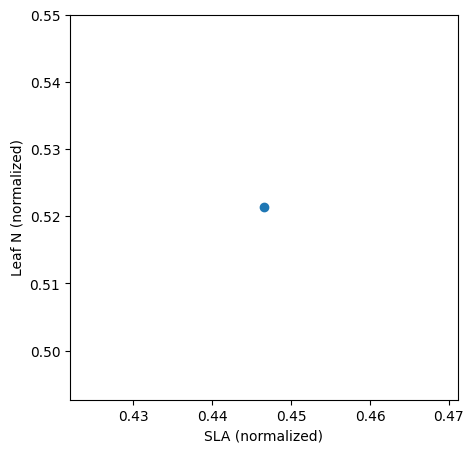

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, max(4, 0.35 * len(res))))
for ax, t in zip(axes, TRAITS):
    d = res.sort_values(f'{t}_pred_norm')
    ax.barh(d['Image'], d[f'{t}_pred_norm'], xerr=d[f'{t}_sigma_norm'], color='#4C9A6A', ecolor='gray')
    ax.set_title(t); ax.set_xlabel('predicted (normalized)')
    ax.tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

# SLA and leaf nitrogen usually rise together (leaf economics spectrum) - a quick sanity check
plt.figure(figsize=(5, 5))
plt.scatter(res['SLA_pred_norm'], res['Leaf_N_pred_norm'])
plt.xlabel('SLA (normalized)'); plt.ylabel('Leaf N (normalized)')
print('Correlation SLA vs Leaf N:', round(res['SLA_pred_norm'].corr(res['Leaf_N_pred_norm']), 3))
plt.show()

# Part 2 — Life stages of a species and how its traits vary

1. **BioCLIP** (zero-shot) labels each photo's life stage (*seedling → juvenile → mature → senescent*) and phenology
   (*vegetative / budding / flowering / fruiting / dormant*). Close-ups of a single leaf or flower are marked
   `Stage_visible = False`, because they show no life stage.
2. You **check the labels** and correct the wrong ones in `stage_corrections.csv`.
3. The analysis joins stages with the PlantTraitNet predictions and shows, per species, how each trait shifts across stages.

**Caveat:** PlantTraitNet was trained on one label per species, so a stage effect here is what the model *reads from the
plant's appearance*, not a measured change. The output table `stage_trait_reference.csv` (p10/p50/p90 per species × stage)
is the starting point for "what normal development looks like" for a species.

Run Part 1 (Steps 1–8) first in the same session: Part 2 reuses its installs, checkpoint and settings.

## Step 10 — Choose the photos
* `STAGE_DATA = 'mine'`: your photos from Part 1. Add a `Species` column to `my_plants.csv` for best results;
  otherwise BioCLIP guesses the species.
* `STAGE_DATA = 'val'`: a slice of the PlantTraitNet validation set (many photos per species).
  Letters `K` + `U` ≈ 750 MB, 694 photos, 21 species with ≥ 20 photos (herbs like *Knautia*, trees like *Ulmus*).
  `Z` adds 441 photos (527 MB). Images go to `/content` (not Drive), so they are re-downloaded each session.

In [12]:
STAGE_DATA  = 'val'          # 'mine' or 'val'
VAL_LETTERS = ['K', 'U']     # only used for 'val'
STAGE_DIR   = f'{RESULTS_DIR}/life_stage_{STAGE_DATA}'
os.makedirs(STAGE_DIR, exist_ok=True)

if STAGE_DATA == 'mine':
    STAGE_IMAGES_CSV, STAGE_IMAGE_ROOT = csv_path, IMAGES_DIR
    STAGE_PREDICTIONS = f'{RESULTS_DIR}/predictions_final.csv'
else:
    import tarfile
    VAL_DIR = '/content/val_data'
    hf_hub_download('ayushi3536/PlantTraitNet', 'val/val.csv', repo_type='dataset', local_dir=VAL_DIR)
    for L in VAL_LETTERS:
        done = f'{VAL_DIR}/.extracted_{L}'
        if not os.path.exists(done):
            tar = hf_hub_download('ayushi3536/PlantTraitNet', f'val/val_images_{L}.tar', repo_type='dataset', local_dir=VAL_DIR)
            with tarfile.open(tar) as t:
                t.extractall(f'{VAL_DIR}/images_{L}', filter='data')
            os.remove(tar)
            open(done, 'w').close()
            print('Extracted', L)
    # Match val.csv rows to extracted files by file name (works whatever the archive's folder layout is)
    found = {}
    for L in VAL_LETTERS:
        for root, _, files in os.walk(f'{VAL_DIR}/images_{L}'):
            for f in files:
                found[f] = os.path.join(root, f)
    val = pd.read_csv(f'{VAL_DIR}/val/val.csv')
    val['Image'] = val['Image'].map(lambda p: found.get(os.path.basename(p)))
    val = val.dropna(subset=['Image'])
    STAGE_IMAGES_CSV, STAGE_IMAGE_ROOT = f'{STAGE_DIR}/val_images.csv', '/'
    val.to_csv(STAGE_IMAGES_CSV, index=False)
    print(len(val), 'images,', val['Species'].nunique(), 'species')
    STAGE_PREDICTIONS = f'{STAGE_DIR}/val_predictions_seed{SEEDS[0]}.csv'
    ckpt = f'{CKPT_DIR}/multitrait_seed{SEEDS[0]}.pth'
    !cd /content/PlantTraitNet/src && PYTHONPATH=/content/mmcv_shim:/content/Depth-Anything-V2 python predict_my_images.py --cfg configs/default.yml --checkpoint "{ckpt}" --images_csv "{STAGE_IMAGES_CSV}" --image_root / --output "{STAGE_PREDICTIONS}" --batch_size 32

val/val.csv: reconstructing file:   0%|          |  0.00B / 27.9MB            

val/val.csv: downloading bytes:           |  0.00B            

val/val_images_K.tar: reconstructing file:   0%|          |  0.00B /  341MB            

val/val_images_K.tar: downloading bytes:           |  0.00B            

Extracted K


val/val_images_U.tar: reconstructing file:   0%|          |  0.00B /  407MB            

val/val_images_U.tar: downloading bytes:           |  0.00B            

Extracted U
694 images, 27 species
xFormers not available
xFormers not available
Using device: cuda
Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
2026-10-19 01:51:36,654 - dinov2 - INFO - using MLP layer as FFN
2026-10-19 01:51:39,428 - dinov2 - INFO - using MLP layer as FFN
2026-10-19 01:51:41,074 - httpx - INFO - HTTP Request: HEAD https://huggingface.co/Jobedo/climplicit/resolve/main/config.json "HTTP/1.1 307 T

## Step 11 — Predict life stage and phenology with BioCLIP
Uses `hf-hub:imageomics/bioclip` (≈ 600 MB, downloaded once per session). For BioCLIP 2, add
`--model hf-hub:imageomics/bioclip-2` to the command (larger, usually more accurate).

In [13]:
!pip install -q open_clip_torch pybioclip
os.makedirs('/content/PlantTraitNet/src/temporal', exist_ok=True)

In [14]:
%%writefile /content/PlantTraitNet/src/temporal/predict_life_stage.py
# ---------------------------------------------------------
# Zero-shot life stage and phenology for plant photos with BioCLIP.
#
# Input CSV columns: Image (path, absolute or relative to --image_root),
#                    optional Species (scientific name).
# Output CSV: the input columns plus
#   Species / Species_source / Species_score  (filled by BioCLIP if missing and --predict_species)
#   Date, DOY                                  (from EXIF DateTimeOriginal, if present)
#   Stage, Stage_conf, Stage_p_<stage>, Stage_index (expected stage, 0 = seedling ... 3 = senescent)
#   Stage_p_closeup, Stage_visible             (close-ups of a leaf/flower show no life stage)
#   Phenology, Phen_conf, Phen_p_<phase>
#
# Each image is scored against prompts that name its own species, e.g.
# "a photo of a seedling of Pyrus communis". These are pseudo-labels: check a sample by hand
# before trusting them.
# ---------------------------------------------------------

import argparse
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import ExifTags, Image, ImageOps

STAGES = {
    "seedling": [
        "a photo of a seedling of {sp}",
        "a photo of a tiny {sp} seedling with cotyledons",
        "a photo of a newly germinated {sp} plant",
    ],
    "juvenile": [
        "a photo of a young {sp} plant",
        "a photo of a juvenile {sp} sapling",
        "a photo of a small immature {sp} plant without flowers",
    ],
    "mature": [
        "a photo of a mature adult {sp} plant",
        "a photo of a fully grown {sp} plant",
        "a photo of a mature {sp} plant in flower or fruit",
    ],
    "senescent": [
        "a photo of a senescent {sp} plant with dying leaves",
        "a photo of a dry withered {sp} plant",
        "a photo of an old declining {sp} plant",
    ],
}

# Scored together with STAGES so that close-ups are not forced into a stage
CLOSEUP = {
    "closeup": [
        "a close-up photo of a single leaf of {sp}",
        "a close-up photo of a flower of {sp}",
        "a photo of fallen leaves of {sp} on the ground",
    ],
}

PHENOLOGY = {
    "vegetative": ["a photo of {sp} with green leaves and no flowers"],
    "budding": ["a photo of {sp} with flower buds"],
    "flowering": ["a photo of {sp} in flower", "a photo of {sp} with open flowers"],
    "fruiting": ["a photo of {sp} with fruits or seeds"],
    "dormant": ["a photo of {sp} with no leaves in winter", "a photo of {sp} with brown autumn leaves"],
}


def parse_args():
    parser = argparse.ArgumentParser("Zero-shot plant life stage with BioCLIP")
    parser.add_argument("--images_csv", type=str, required=True)
    parser.add_argument("--image_root", type=str, default=".")
    parser.add_argument("--output", type=str, default="life_stages.csv")
    parser.add_argument("--model", type=str, default="hf-hub:imageomics/bioclip",
                        help="open_clip model id, e.g. hf-hub:imageomics/bioclip-2 for BioCLIP 2")
    parser.add_argument("--species_col", type=str, default="Species")
    parser.add_argument("--predict_species", action="store_true",
                        help="Fill missing species with BioCLIP's Tree-of-Life classifier (needs pybioclip)")
    parser.add_argument("--max_closeup", type=float, default=0.5,
                        help="Images with P(closeup) above this are marked Stage_visible=False")
    parser.add_argument("--batch_size", type=int, default=32)
    return parser.parse_args()


def exif_date(path):
    try:
        exif = Image.open(path).getexif()
        raw = exif.get_ifd(ExifTags.IFD.Exif).get(36867) or exif.get(306)  # DateTimeOriginal, DateTime
        return datetime.strptime(str(raw).strip(), "%Y:%m:%d %H:%M:%S") if raw else None
    except Exception:
        return None


def predict_species(paths):
    from bioclip import Rank, TreeOfLifeClassifier

    classifier = TreeOfLifeClassifier()
    names, scores = [], []
    for p in paths:
        top = classifier.predict([str(p)], Rank.SPECIES, k=1)[0]
        names.append(top["species"])
        scores.append(float(top["score"]))
    return names, scores


class PromptScorer:
    """Caches averaged text embeddings for each (species, label set)."""

    def __init__(self, model, tokenizer, device):
        self.model, self.tokenizer, self.device = model, tokenizer, device
        self.cache = {}

    @torch.no_grad()
    def text_features(self, species, labels, name):
        key = (species, name)
        if key not in self.cache:
            feats = []
            for templates in labels.values():
                tokens = self.tokenizer([t.format(sp=species) for t in templates]).to(self.device)
                f = self.model.encode_text(tokens)
                f = f / f.norm(dim=-1, keepdim=True)
                f = f.mean(dim=0)
                feats.append(f / f.norm())
            self.cache[key] = torch.stack(feats)
        return self.cache[key]

    @torch.no_grad()
    def probs(self, image_feat, species, labels, name):
        text = self.text_features(species, labels, name)
        logits = self.model.logit_scale.exp() * image_feat @ text.T
        return logits.softmax(dim=-1).cpu().numpy()


def main():
    import open_clip

    args = parse_args()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    df = pd.read_csv(args.images_csv)
    paths = [Path(p) if Path(p).is_absolute() else Path(args.image_root) / p for p in df["Image"]]

    if args.species_col not in df.columns:
        df[args.species_col] = np.nan
    missing = df[args.species_col].isna()
    df["Species_source"] = np.where(missing, "unknown", "given")
    df["Species_score"] = np.nan
    if missing.any() and args.predict_species:
        print(f"Predicting species for {missing.sum()} images with BioCLIP Tree-of-Life")
        names, scores = predict_species([p for p, m in zip(paths, missing) if m])
        df.loc[missing, args.species_col] = names
        df.loc[missing, "Species_score"] = scores
        df.loc[missing, "Species_source"] = "bioclip"
    df[args.species_col] = df[args.species_col].fillna("plant")

    dates = [exif_date(p) for p in paths]
    df["Date"] = [d.date().isoformat() if d else None for d in dates]
    df["DOY"] = [d.timetuple().tm_yday if d else np.nan for d in dates]

    model, _, preprocess = open_clip.create_model_and_transforms(args.model)
    tokenizer = open_clip.get_tokenizer(args.model)
    model.to(device).eval()
    scorer = PromptScorer(model, tokenizer, device)

    stage_labels = {**STAGES, **CLOSEUP}
    stage_p = np.zeros((len(df), len(stage_labels)))
    phen_p = np.zeros((len(df), len(PHENOLOGY)))
    for start in range(0, len(df), args.batch_size):
        idx = range(start, min(start + args.batch_size, len(df)))
        images = torch.stack([
            preprocess(ImageOps.exif_transpose(Image.open(paths[i])).convert("RGB")) for i in idx
        ]).to(device)
        with torch.no_grad():
            feats = model.encode_image(images)
            feats = feats / feats.norm(dim=-1, keepdim=True)
        for k, i in enumerate(idx):
            sp = df[args.species_col].iloc[i]
            stage_p[i] = scorer.probs(feats[k], sp, stage_labels, "stage")
            phen_p[i] = scorer.probs(feats[k], sp, PHENOLOGY, "phen")
        print(f"Processed {idx[-1] + 1}/{len(df)} images")

    stage_names, phen_names = list(STAGES), list(PHENOLOGY)
    closeup_p = stage_p[:, -1]
    stage_p = stage_p[:, :-1] / stage_p[:, :-1].sum(1, keepdims=True)
    df["Stage"] = [stage_names[j] for j in stage_p.argmax(1)]
    df["Stage_conf"] = stage_p.max(1)
    df["Stage_index"] = stage_p @ np.arange(len(stage_names))
    for j, s in enumerate(stage_names):
        df[f"Stage_p_{s}"] = stage_p[:, j]
    df["Stage_p_closeup"] = closeup_p
    df["Stage_visible"] = closeup_p <= args.max_closeup
    df["Phenology"] = [phen_names[j] for j in phen_p.argmax(1)]
    df["Phen_conf"] = phen_p.max(1)
    for j, s in enumerate(phen_names):
        df[f"Phen_p_{s}"] = phen_p[:, j]

    df.to_csv(args.output, index=False)
    print(f"Saved life stages to {args.output}")
    print(df[df["Stage_visible"]]["Stage"].value_counts().to_string())
    print(f"Stage not visible (close-up): {(~df['Stage_visible']).sum()} images")


if __name__ == "__main__":
    main()

Writing /content/PlantTraitNet/src/temporal/predict_life_stage.py


In [15]:
STAGES_CSV = f'{STAGE_DIR}/life_stages.csv'
species_flag = '--predict_species' if STAGE_DATA == 'mine' else ''
!cd /content/PlantTraitNet/src && python temporal/predict_life_stage.py --images_csv "{STAGE_IMAGES_CSV}" --image_root "{STAGE_IMAGE_ROOT}" --output "{STAGES_CSV}" {species_flag}
stages = pd.read_csv(STAGES_CSV)
stages[['Image', 'Species', 'Stage', 'Stage_conf', 'Stage_p_closeup', 'Stage_visible', 'Phenology', 'Phen_conf']].head(10)

Using device: cuda
open_clip_config.json: 100% 469/469 [00:00<00:00, 2.60MB/s]

open_clip_pytorch_model.bin: downloading bytes:  95% 567M/599M [00:02<00:00, 347MB/s, 47.4MB/s  ]
open_clip_pytorch_model.bin: reconstructing file:  45% 268M/599M [00:04<00:05, 60.4MB/s]
open_clip_pytorch_model.bin: downloading bytes: 100% 567M/567M [00:05<00:00, 104MB/s, 50.6MB/s  ]
open_clip_pytorch_model.bin: reconstructing file: 100% 599M/599M [00:05<00:00, 110MB/s, 51.0MB/s  ]
Processed 32/694 images
Processed 64/694 images
Processed 96/694 images
Processed 128/694 images
Processed 160/694 images
Processed 192/694 images
Processed 224/694 images
Processed 256/694 images
Processed 288/694 images
Processed 320/694 images
Processed 352/694 images
Processed 384/694 images
Processed 416/694 images
Processed 448/694 images
Processed 480/694 images
Processed 512/694 images
Processed 544/694 images
Processed 576/694 images
Processed 608/694 images
Processed 640/694 images
Processed 672/694 images
Processed 694

,Image,Species,Stage,Stage_conf,Stage_p_closeup,Stage_visible,Phenology,Phen_conf
0,/content/val_data/images_U/U/Ulmus_alata/e95f0...,Ulmus alata,senescent,0.935718,0.017276,True,budding,0.418388
1,/content/val_data/images_U/U/Ulmus_alata/b2abc...,Ulmus alata,senescent,0.674866,0.247668,True,flowering,0.856077
2,/content/val_data/images_K/K/Knautia_arvensis/...,Knautia arvensis,senescent,0.648677,0.405027,True,dormant,0.432075
3,/content/val_data/images_K/K/Kraussia_floribun...,Kraussia floribunda,senescent,0.514950,0.012018,True,flowering,0.595490
4,/content/val_data/images_K/K/Kernera_saxatilis...,Kernera saxatilis,senescent,0.732913,0.389417,True,flowering,0.612732
5,/content/val_data/images_K/K/Kernera_saxatilis...,Kernera saxatilis,mature,0.931307,0.074545,True,fruiting,0.395898
6,/content/val_data/images_U/U/Ulex_gallii/obs_1...,Ulex gallii,senescent,0.641916,0.077586,True,flowering,0.700496
7,/content/val_data/images_U/U/Ulmus_alata/d85fa...,Ulmus alata,mature,0.960484,0.040931,True,flowering,0.435932
8,/content/val_data/images_K/K/Kernera_saxatilis...,Kernera saxatilis,seedling,0.702480,0.094367,True,vegetative,0.501397
9,/content/val_data/images_K/K/Kigelia_africana/...,Kigelia africana,juvenile,0.894901,0.000428,True,flowering,0.819303


## Step 12 — Check the stage labels
Zero-shot labels are pseudo-labels. In testing, BioCLIP got whole-plant and crowded photos right but sometimes
mislabelled back-lit or partial views. The grid shows a random sample. To correct a label, open
**`stage_corrections.csv`** in `STAGE_DIR` on Drive and fill `Stage_manual` with `seedling`, `juvenile`, `mature`,
`senescent` or `closeup` (stage not visible). Corrections are kept when you re-run Step 11.

Created /content/drive/MyDrive/PlantTraitNet/results/life_stage_val/stage_corrections.csv


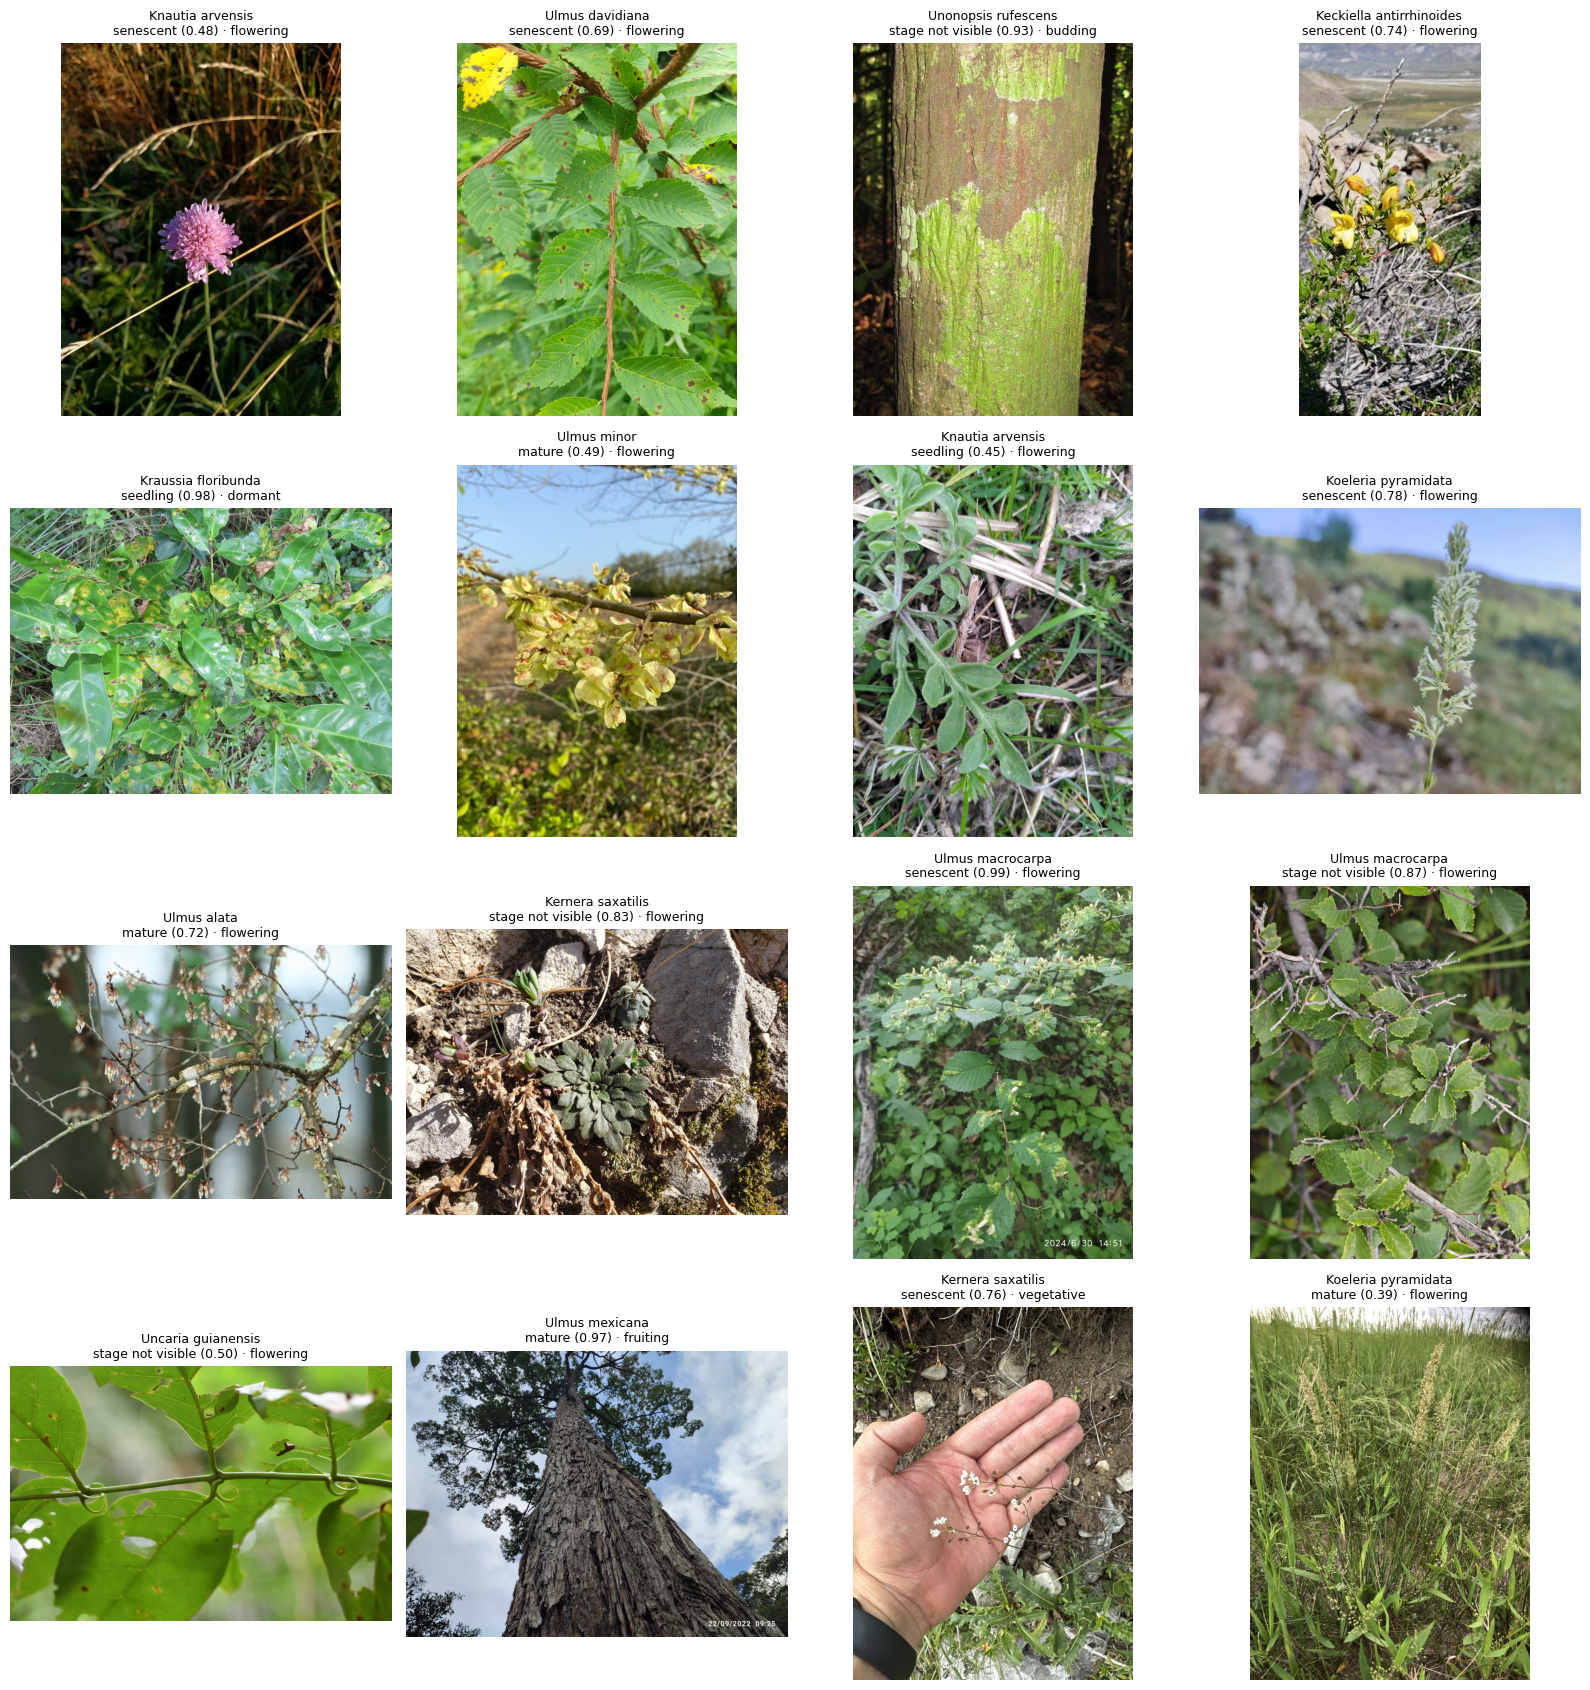

In [16]:
CORR_CSV = f'{STAGE_DIR}/stage_corrections.csv'
if not os.path.exists(CORR_CSV):
    stages[['Image', 'Species', 'Stage']].assign(Stage_manual='').to_csv(CORR_CSV, index=False)
    print('Created', CORR_CSV)

sample = stages.sample(min(16, len(stages)), random_state=0)
fig, axes = plt.subplots(4, 4, figsize=(16, 17), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    p = r['Image'] if os.path.isabs(r['Image']) else os.path.join(STAGE_IMAGE_ROOT, r['Image'])
    ax.imshow(ImageOps.exif_transpose(Image.open(p)).convert('RGB'))
    stage = r['Stage'] if r['Stage_visible'] else 'stage not visible'
    ax.set_title(f"{r['Species']}\n{stage} ({r['Stage_conf']:.2f}) · {r['Phenology']}", fontsize=9)
plt.tight_layout(); plt.show()

## Step 13 — How traits vary across life stages
Writes to `STAGE_DIR`:
* `stage_trait_reference.csv`: per species × stage × trait: `n`, mean, uncertainty-weighted mean, sd, p10/p50/p90
* `stage_effect_pooled.csv`: within-species shift per stage (trait minus that species' mean), averaged over species
* `species_stage_trend.csv`: per species, Spearman ρ between each trait and the expected stage (`Stage_index`)

In [21]:
%%writefile /content/PlantTraitNet/src/temporal/stage_trait_analysis.py
# ---------------------------------------------------------
# How do predicted traits vary across the life stages of a species?
#
# Joins PlantTraitNet predictions (predict_my_images.py / predictions_final.csv) with
# life stages (predict_life_stage.py) on the Image column and writes:
#   stage_trait_reference.csv  per Species x Stage x Trait: n, mean, uncertainty-weighted mean, sd, p10/p50/p90
#   stage_effect_pooled.csv    within-species shift per stage (trait minus species mean), pooled over species
#   species_stage_trend.csv    per species: Spearman correlation of each trait with Stage_index
#   stage_counts.png, stage_effect_pooled.png, stage_trajectories.png
#
# Note: PlantTraitNet was trained on species-level labels, so any stage effect here is what the
# model reads from the plant's appearance, not a measured change.
# ---------------------------------------------------------

import argparse
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

STAGE_ORDER = ["seedling", "juvenile", "mature", "senescent"]
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"


def parse_args():
    parser = argparse.ArgumentParser("Trait variation across life stages")
    parser.add_argument("--predictions", type=str, required=True)
    parser.add_argument("--stages", type=str, required=True)
    parser.add_argument("--output_dir", type=str, default="stage_analysis")
    parser.add_argument("--traits", nargs="+", default=["Height", "LeafArea", "SLA", "Leaf_N"])
    parser.add_argument("--min_stage_conf", type=float, default=0.4,
                        help="Drop images whose top stage probability is below this")
    parser.add_argument("--sigma_quantile", type=float, default=0.95,
                        help="Drop a trait value when its uncertainty is above this quantile")
    parser.add_argument("--min_per_stage", type=int, default=3)
    parser.add_argument("--top_species", type=int, default=8)
    return parser.parse_args()


def style(ax):
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelcolor=INK)


def load(args):
    preds = pd.read_csv(args.predictions)
    stages = pd.read_csv(args.stages)
    stages = stages[[c for c in stages.columns if c == "Image" or c not in preds.columns]]
    df = preds.merge(stages, on="Image", how="inner")
    print(f"Joined {len(df)} images")

    # Hand corrections: a Stage_manual value (a stage name or "closeup") overrides the model
    if "Stage_manual" in df.columns:
        # An empty corrections file is read as an all-NaN float column, so clean it as strings
        manual_stage = df["Stage_manual"].fillna("").astype(str).str.strip().str.lower()
        manual = manual_stage != ""
        df.loc[manual, "Stage"] = manual_stage[manual]
        df.loc[manual, "Stage_conf"] = 1.0
        df.loc[manual, "Stage_visible"] = df.loc[manual, "Stage"] != "closeup"
        print(f"Using {manual.sum()} hand-corrected stages")
    if "Stage_visible" in df.columns:
        df = df[df["Stage_visible"].astype(bool)]
    df = df[df["Stage_conf"] >= args.min_stage_conf].copy()
    print(f"{len(df)} images with a visible stage and stage confidence >= {args.min_stage_conf}")
    for t in args.traits:
        sigma = df[f"{t}_sigma_norm"]
        df.loc[sigma > sigma.quantile(args.sigma_quantile), f"{t}_pred_norm"] = np.nan
    df["Stage"] = pd.Categorical(df["Stage"], STAGE_ORDER, ordered=True)
    return df


def reference_table(df, traits):
    rows = []
    for (sp, st), g in df.groupby(["Species", "Stage"], observed=True):
        for t in traits:
            v, s = g[f"{t}_pred_norm"], g[f"{t}_sigma_norm"]
            ok = v.notna()
            if not ok.any():
                continue
            w = 1.0 / s[ok] ** 2
            rows.append({
                "Species": sp, "Stage": st, "Trait": t, "n": int(ok.sum()),
                "mean": v[ok].mean(), "wmean": float(np.sum(w * v[ok]) / np.sum(w)),
                "sd": v[ok].std(), "p10": v[ok].quantile(0.1),
                "p50": v[ok].median(), "p90": v[ok].quantile(0.9),
            })
    ref = pd.DataFrame(rows)
    if not ref.empty:
        ref["Stage"] = pd.Categorical(ref["Stage"], STAGE_ORDER, ordered=True)
    return ref


def pooled_effect(ref, min_per_stage):
    # Keep species seen in at least two stages, centre each species on its own mean,
    # then average the shifts per stage across species.
    ref = ref[ref["n"] >= min_per_stage].copy()
    n_stages = ref.groupby(["Species", "Trait"])["Stage"].transform("nunique")
    ref = ref[n_stages >= 2]
    ref["shift"] = ref["wmean"] - ref.groupby(["Species", "Trait"])["wmean"].transform("mean")
    out = ref.groupby(["Trait", "Stage"], observed=True)["shift"].agg(["mean", "std", "count"]).reset_index()
    out["se"] = out["std"] / np.sqrt(out["count"])
    return out.rename(columns={"count": "n_species"})


def species_trends(df, traits, min_n=8):
    rows = []
    for sp, g in df.groupby("Species"):
        for t in traits:
            d = g[[f"{t}_pred_norm", "Stage_index"]].dropna()
            if len(d) < min_n or d["Stage_index"].nunique() < 2:
                continue
            rho, p = spearmanr(d["Stage_index"], d[f"{t}_pred_norm"])
            rows.append({"Species": sp, "Trait": t, "n": len(d), "spearman_rho": rho, "p_value": p})
    if not rows:
        print(f"No species has {min_n}+ images with a visible stage; species_stage_trend.csv is empty")
    return pd.DataFrame(rows, columns=["Species", "Trait", "n", "spearman_rho", "p_value"])


def plot_counts(df, out):
    counts = df["Stage"].value_counts().reindex(STAGE_ORDER, fill_value=0)
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(counts.index, counts.values, color=SERIES[0], width=0.6)
    for x, v in enumerate(counts.values):
        ax.text(x, v, str(v), ha="center", va="bottom", color=INK, fontsize=9)
    ax.set_title("Images per predicted life stage", color=INK, loc="left")
    ax.set_ylabel("images", color=MUTED)
    style(ax)
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def plot_pooled(eff, traits, out):
    fig, axes = plt.subplots(1, len(traits), figsize=(4 * len(traits), 3.6), sharey=True)
    for ax, t in zip(np.atleast_1d(axes), traits):
        e = eff[eff["Trait"] == t].set_index("Stage").reindex(STAGE_ORDER)
        x = np.arange(len(STAGE_ORDER))
        ax.axhline(0, color=MUTED, linewidth=1)
        ax.errorbar(x, e["mean"], yerr=e["se"], color=SERIES[0], marker="o", markersize=8,
                    linewidth=2, capsize=3)
        ax.set_xticks(x, STAGE_ORDER, rotation=20)
        ax.set_title(t, color=INK, loc="left")
        style(ax)
    np.atleast_1d(axes)[0].set_ylabel("shift from species mean\n(normalized, ± SE)", color=MUTED)
    fig.suptitle("Within-species trait shift by life stage", color=INK, x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def plot_trajectories(ref, traits, top, min_per_stage, out):
    r = ref[ref["n"] >= min_per_stage]
    coverage = r.groupby("Species")["Stage"].nunique()
    size = r.groupby("Species")["n"].sum()
    species = size[coverage[coverage >= 2].index].sort_values(ascending=False).head(top).index
    if len(species) == 0:
        print("No species has enough images in two or more stages; skipping trajectory plot")
        return
    fig, axes = plt.subplots(1, len(traits), figsize=(4 * len(traits), 4))
    x_of = {s: i for i, s in enumerate(STAGE_ORDER)}
    for ax, t in zip(np.atleast_1d(axes), traits):
        for k, sp in enumerate(species):
            d = r[(r["Species"] == sp) & (r["Trait"] == t)].sort_values("Stage")
            ax.plot([x_of[s] for s in d["Stage"]], d["wmean"], color=SERIES[k], marker=MARKERS[k],
                    markersize=8, linewidth=2, label=sp)
        ax.set_xticks(range(len(STAGE_ORDER)), STAGE_ORDER, rotation=20)
        ax.set_title(t, color=INK, loc="left")
        style(ax)
    np.atleast_1d(axes)[0].set_ylabel("predicted trait (normalized)", color=MUTED)
    handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(4, len(species)), frameon=False,
               fontsize=9, labelcolor=INK)
    fig.suptitle("Trait trajectory across life stages (top species)", color=INK, x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0.12, 1, 1))
    fig.savefig(out, dpi=150)
    plt.close(fig)


def main():
    args = parse_args()
    out = Path(args.output_dir)
    out.mkdir(parents=True, exist_ok=True)

    df = load(args)
    ref = reference_table(df, args.traits)
    eff = pooled_effect(ref, args.min_per_stage)
    trends = species_trends(df, args.traits)

    ref.to_csv(out / "stage_trait_reference.csv", index=False)
    eff.to_csv(out / "stage_effect_pooled.csv", index=False)
    trends.to_csv(out / "species_stage_trend.csv", index=False)

    plot_counts(df, out / "stage_counts.png")
    if not eff.empty:
        plot_pooled(eff, args.traits, out / "stage_effect_pooled.png")
    plot_trajectories(ref, args.traits, args.top_species, args.min_per_stage, out / "stage_trajectories.png")

    print(f"Saved tables and plots to {out}")
    if not eff.empty:
        print(eff.pivot(index="Stage", columns="Trait", values="mean").round(3).to_string())


if __name__ == "__main__":
    main()


Overwriting /content/PlantTraitNet/src/temporal/stage_trait_analysis.py


Joined 694 images
Using 0 hand-corrected stages
547 images with a visible stage and stage confidence >= 0.4
Saved tables and plots to /content/drive/MyDrive/PlantTraitNet/results/life_stage_val
Trait      Height  LeafArea  Leaf_N    SLA
Stage                                     
seedling   -0.013    -0.006  -0.009 -0.009
juvenile   -0.002     0.002   0.009  0.013
mature      0.024     0.006  -0.002 -0.001
senescent  -0.006    -0.001   0.005  0.002


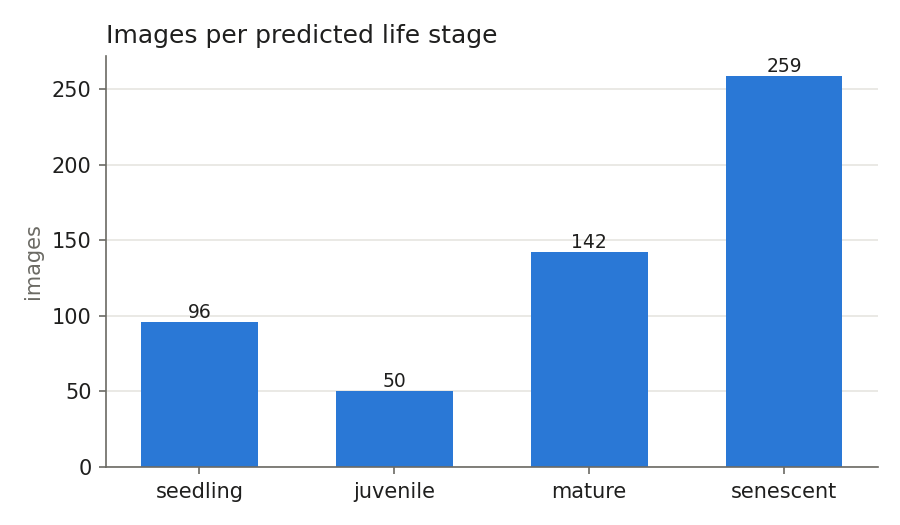

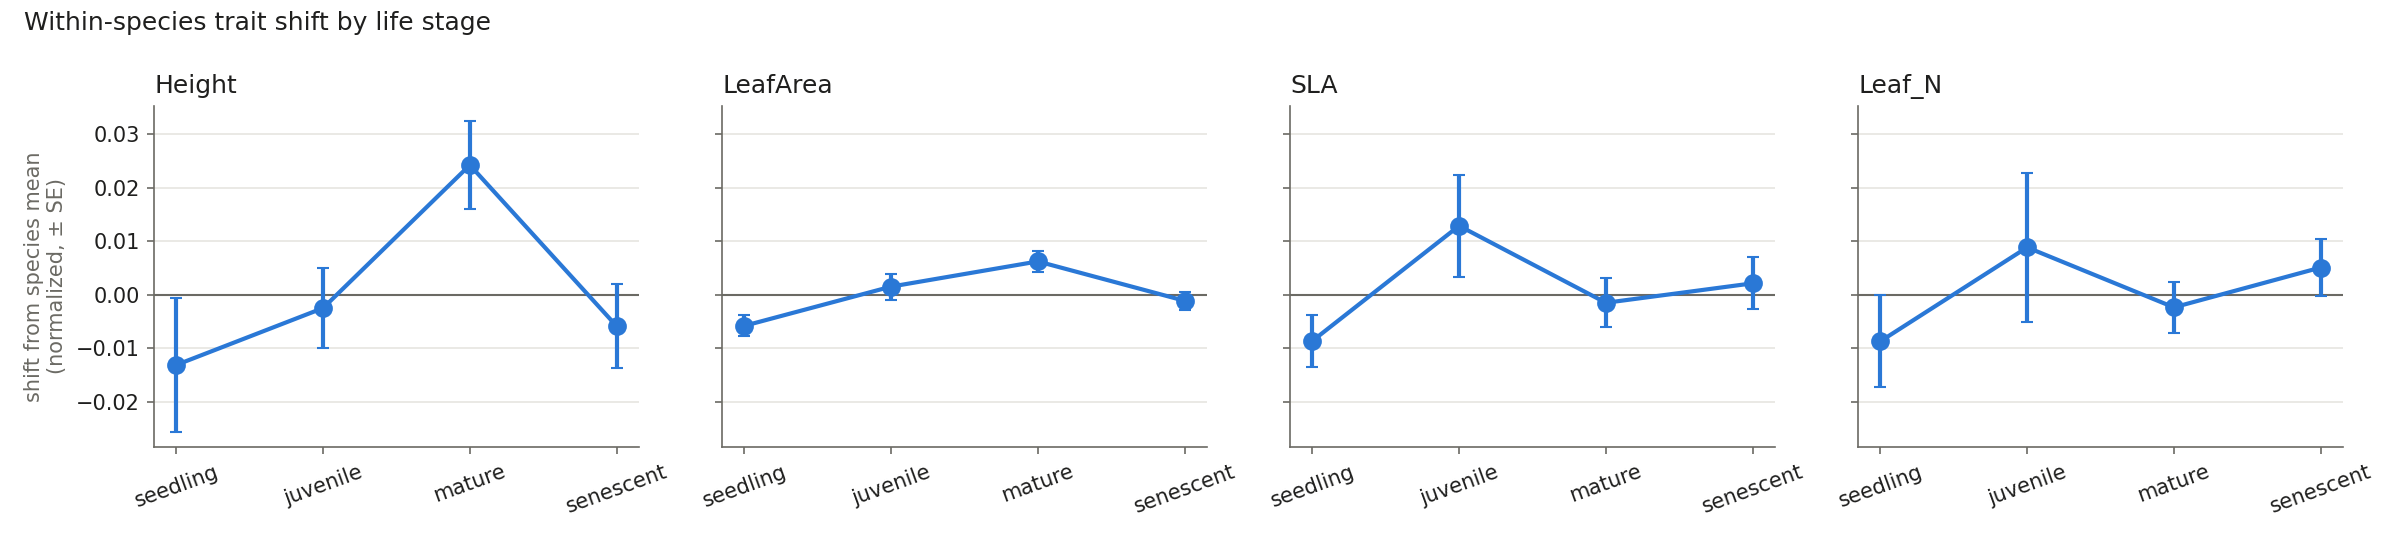

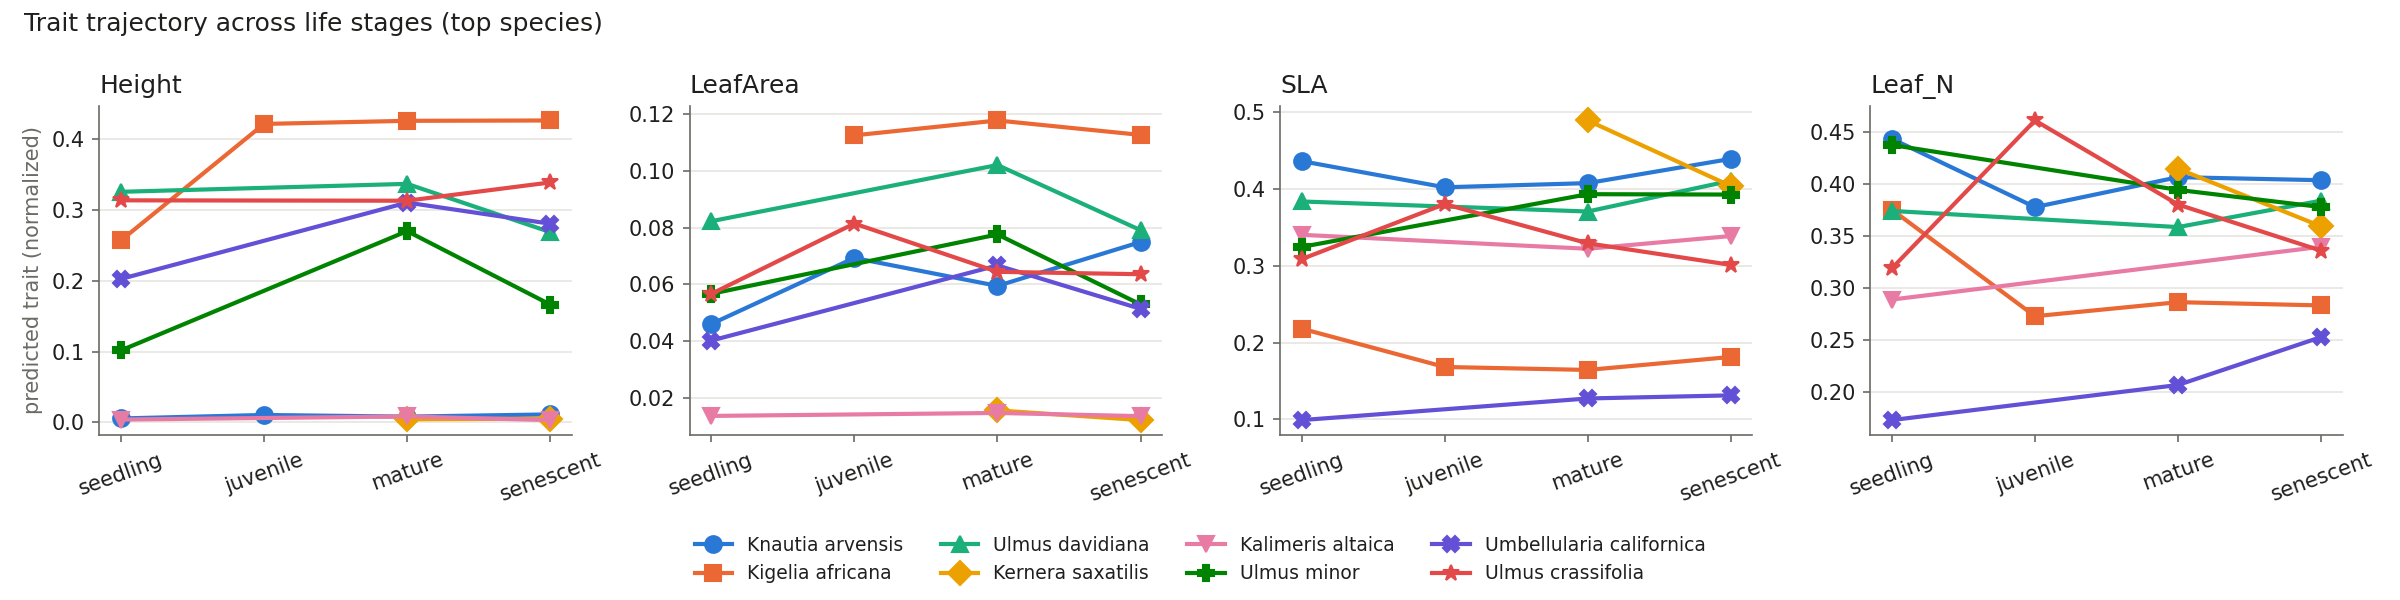

,Species,Trait,n,spearman_rho,p_value
64,Ulmus mexicana,Height,8,-0.905,0.002
28,Kraussia floribunda,Height,17,-0.640,0.006
83,Umbellularia californica,Leaf_N,28,0.472,0.011
17,Knautia arvensis,LeafArea,39,0.402,0.011
8,Kernera saxatilis,Height,38,0.400,0.013
16,Knautia arvensis,Height,39,0.383,0.016
10,Kernera saxatilis,SLA,23,-0.477,0.021
25,Koeleria vallesiana,LeafArea,13,0.610,0.027
29,Kraussia floribunda,LeafArea,17,-0.534,0.027
7,Keckiella antirrhinoides,Leaf_N,16,0.550,0.027


In [22]:
corr = pd.read_csv(CORR_CSV)[['Image', 'Stage_manual']]
reviewed = stages.drop(columns='Stage_manual', errors='ignore').merge(corr, on='Image', how='left')
REVIEWED_CSV = f'{STAGE_DIR}/life_stages_reviewed.csv'
reviewed.to_csv(REVIEWED_CSV, index=False)

!cd /content/PlantTraitNet/src && python temporal/stage_trait_analysis.py --predictions "{STAGE_PREDICTIONS}" --stages "{REVIEWED_CSV}" --output_dir "{STAGE_DIR}"

from IPython.display import Image as ShowImage, display
for name in ['stage_counts.png', 'stage_effect_pooled.png', 'stage_trajectories.png']:
    if os.path.exists(f'{STAGE_DIR}/{name}'):
        display(ShowImage(f'{STAGE_DIR}/{name}'))
pd.read_csv(f'{STAGE_DIR}/species_stage_trend.csv').sort_values('p_value').head(15).round(3)

### Reading the results
* **Expected if the model reads development:** height and leaf area rise from seedling to mature; SLA is often
  highest in seedlings (thin, cheap leaves) and lower in mature plants.
* A flat line means the model gives a species about the same prediction at every stage. With species-level training
  labels that is a likely outcome, and it is a finding in itself.
* Few images per stage give wide error bars. Add more `VAL_LETTERS` or lower `--min_per_stage`.
* Next step towards "healthy development": compare each new photo with its species × stage p10–p90 range in
  `stage_trait_reference.csv`, and add environment (climate, site) to explain deviations.

### Next ideas
* Add a `Species` or `Site` column to `my_plants.csv` in Drive, re-run Steps 7–9, then `res.groupby('Species').mean(numeric_only=True)`.
* Set `SEEDS = [0, 100, 200]` in Step 2 for an ensemble; `*_seed_std` shows where the three models disagree.
* All CSVs are in `MyDrive/PlantTraitNet/results/` for further analysis.